In [1]:
#1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
 #2. Load Dataset
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,52:06.0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,04:56.0,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,45:00.0,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,22:21.0,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,47:00.0,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
#3. Data Preprocessing
#Remove Missing Values
df = df.dropna()
#Remove Unnecessary Column
df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')
#Convert Pickup Datetime
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df = df.drop(columns=['pickup_datetime'])
#Remove Invalid Values and Outliers
df = df[(df["passenger_count"] > 0) & (df["passenger_count"] <= 6)]
df = df[
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90))
]

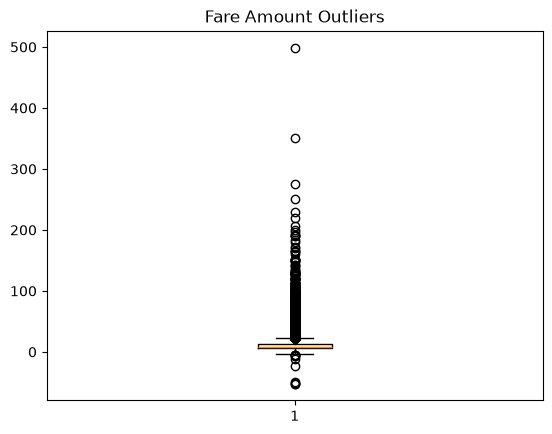

In [4]:
#4. Identify Outliers Using Box Plot
plt.boxplot(df["fare_amount"])
plt.title("Fare Amount Outliers")
plt.show()

In [5]:
#5.Split Dataset
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
#6.Implement Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print(y_pred_lr)

[12.60095259 12.22137835 12.72060801 ... 12.31159799 11.65547248
 12.52762617]


In [7]:
#7.Implement Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test) 

In [8]:
#8.Evaluate Models
print("Linear Regression")

print("R2 Score:", r2_score(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MSE:", mean_squared_error(y_test, y_pred_lr))


print("\nRandom Forest Regression")

print("R2 Score:", r2_score(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MSE:", mean_squared_error(y_test, y_pred_rf))

Linear Regression
R2 Score: 0.01677897672336126
RMSE: 9.89002080362255
MSE: 97.81251149608683

Random Forest Regression
R2 Score: 0.7764084601597177
RMSE: 4.716277065641557
MSE: 22.243269359896534


In [17]:
result = pd.DataFrame()

result["Actual Fare"] = y_test.values
result["Linear Regression"] = y_pred_lr
result["Random Forest"] = y_pred_rf

display(result)

,Actual Fare,Linear Regression,Random Forest
0,7.00,12.600953,6.8420
1,4.00,12.221378,7.2260
2,32.83,12.720608,25.3976
3,6.50,12.456644,7.0400
4,12.70,9.129189,11.8610
...,...,...,...
39851,8.90,10.360294,9.1670
39852,20.10,11.023814,17.3330
39853,12.50,12.311598,10.6600
39854,4.00,11.655472,5.2200


In [13]:
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014
...,...,...,...,...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1,10,28,10,2012
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1,1,14,3,2014
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2,0,29,6,2009
199998,14.5,-73.997124,40.725452,-73.983215,40.695416,1,14,20,5,2015


In [19]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

display(result)

,Actual Fare,Linear Regression,Random Forest
0,7.00,12.600953,6.842000
1,4.00,12.221378,7.226000
2,32.83,12.720608,25.397600
3,6.50,12.456644,7.040000
4,12.70,9.129189,11.861000
5,4.50,10.852861,6.624000
6,38.50,9.364279,41.086400
7,5.00,12.652994,5.490000
8,5.30,10.585939,8.564100
9,4.50,13.144154,7.005000
